# Assignment 5 — ANOVA and Simple Linear Regression
**Group members:** Daniel Munteanu, Josip Brljevic, Luca Mouawad, Zygmunt Tadeusz Kwasniewicz

## Table of contents
1. Part 1 — Composite strength across curing methods
2. Part 2 — Diagnostics, post-hoc comparisons, and magnitude
3. Part 3 — Pump flow and energy use
4. Part 4 — Regression diagnostics and prediction
5. Part 5 — AI-use and conclusion

In [1]:
# py -m pip install scipy statsmodels matplotlib
from IPython.display import display, Markdown
import scipy.stats as stats
from statsmodels.stats.proportion import proportion_confint
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import math
import statsmodels.api as sm


# Part 1 — Composite strength across curing methods
#### The file *assignment05_composite_strength.csv* contains independent composite specimens cured by four methods. The response is `strength_mpa`; the factor is `curing_method`.

### a) Identify the population, observational unit, response, factor, and factor levels. Explain what additional design information would be needed for a causal claim about curing method.



**Population:** composite specimens of this type that could be cured by each of the four methods (one population per method). \
**Observational unit:** one composite specimen. \
**Response:** strength, strength_mpa, measured in MPa. \
**Factor:** curing_method, with four levels: ambient, thermal, uv and hybrid

To claim that curing method causes differences in strength, we would need to know that specimens were randomly assigned to the four methods, and that other factors such as material batch, specimen size, test date, were kept the same or balanced across groups. Specimens should also have been tested in random order. The data only say the specimens are independent, not how they were allocated.

### b) Report group sample sizes, means, and sample standard deviations. Create side‑by‑side boxplots and describe between‑group differences and within‑group variation.

,n,mean,sd
curing_method,,,
ambient,24,52.18,5.55
thermal,24,55.82,4.09
uv,24,55.42,3.44
hybrid,24,63.57,6.20


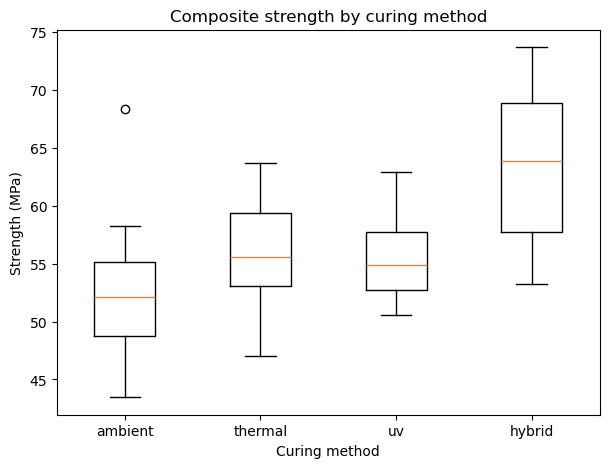

In [2]:
composite = pd.read_csv("./assignment05_composite_strength.csv")
order = ["ambient", "thermal", "uv", "hybrid"]

summary = (composite.groupby("curing_method")["strength_mpa"]
           .agg(n="count", mean="mean", sd="std")
           .loc[order]
           .round(2))
display(summary)

fig, ax = plt.subplots(figsize=(7, 5))
ax.boxplot([composite.loc[composite["curing_method"] == m, "strength_mpa"] for m in order])
ax.set_xticklabels(order)
ax.set_xlabel("Curing method")
ax.set_ylabel("Strength (MPa)")
ax.set_title("Composite strength by curing method")
plt.show()


**Between-group differences:** hybrid curing has the highest mean strength (63.6 MPa), about 8 MPa above thermal and UV and 11 MPa above ambient. Thermal and UV are almost the same, and ambient has the lowest mean. In the boxplots the hybrid box sits clearly above the others, with little overlap with the ambient box, while the thermal and UV boxes overlap almost completely.

**Within-group variation:** the spread differs between groups. UV is the most consistent (SD 3.4 MPa) and thermal is similar, while ambient and hybrid vary more. The largest SD is less than twice the smallest. Even so, the within-group variation is large compared with the differences between thermal, UV and ambient, so the boxplots alone can't tell us whether those three really differ. Ambient has one high outlier, which is well above the rest of its group.

### c) State the one‑way ANOVA hypotheses. Explain why a collection of unadjusted pairwise *t*‑tests is a poor default.

Let $\mu_{\text{ambient}}, \mu_{\text{thermal}}, \mu_{\text{uv}}, \mu_{\text{hybrid}}$ be the population mean strengths for the four curing methods.

- $H_0: \mu_{\text{ambient}} = \mu_{\text{thermal}} = \mu_{\text{uv}} = \mu_{\text{hybrid}}$
- $H_1:$ not all means are the same
- $\alpha = 0.05$

$H_1$ does not say that all four means are different. It only says they are not all equal. 

**Why unadjusted pairwise t-tests are a poor default:** with 4 groups there are $\binom{4}{2} = 6$ pairs to compare. Each test has a 5% chance of a false positive when its null is true, and these chances add up across tests. If all four means were truly equal and the tests were independent, the chance of at least one false "significant" difference would be

$$1 - 0.95^6 \approx 0.26,$$

so about 26%, not 5%. The tests share groups, so they are not exactly independent, but the error rate is still well above 5%. The more groups there are, the worse this gets. Each pairwise test also estimates the variance from only two groups, while ANOVA pools the within-group variation from all 96 specimens, which gives a more precise estimate. The one-way ANOVA tests all the means together in a single test at level $\alpha = 0.05$. If it rejects, pairwise comparisons should be done with an adjustment for multiple testing.

### d) Fit the classical one‑way model and produce an ANOVA table. Report sums of squares, degrees of freedom, mean squares, *F*, *p* and explain what the *F* ratio compares.

In [3]:
import statsmodels.formula.api as smf
import statsmodels.api as sm

model = smf.ols("strength_mpa ~ C(curing_method)", data=composite).fit()
anova_table = sm.stats.anova_lm(model, typ=2)

anova_table["mean_sq"] = anova_table["sum_sq"] / anova_table["df"]
anova_table.loc["Total", ["sum_sq", "df"]] = [anova_table["sum_sq"].sum(), anova_table["df"].sum()]
anova_table = anova_table[["sum_sq", "df", "mean_sq", "F", "PR(>F)"]]
display(anova_table.round(4))

,sum_sq,df,mean_sq,F,PR(>F)
C(curing_method),1682.0804,3.0,560.6935,22.9423,0.0
Residual,2248.4130,92.0,24.4393,NaN,NaN
Total,3930.4934,95.0,NaN,NaN,NaN


The classical one-way model is $Y_{ij} = \mu_i + \varepsilon_{ij}$, where $Y_{ij}$ is the strength of specimen $j$ cured by method $i$, $\mu_i$ is the mean strength for method $i$, and the errors $\varepsilon_{ij}$ are independent and normal with a common variance $\sigma^2$.

- **Sums of squares:** the total variation in strength (3930.5) splits into variation *between* curing methods (1682.1) and variation *within* methods (2248.4).
- **Degrees of freedom:** between = $k - 1 = 3$, within = $N - k = 96 - 4 = 92$, total = $N - 1 = 95$.
- **Mean squares:** $MS_{\text{between}} = 1682.1/3 = 560.7$ and $MS_{\text{within}} = 2248.4/92 = 24.4$. $MS_{\text{within}}$ is the pooled estimate of $\sigma^2$, so the common within-group SD is about $\sqrt{24.4} \approx 4.9$ MPa.
- **F and p:** $F = 560.7 / 24.4 = 22.9$ on (3, 92) degrees of freedom, with $p \approx 3.6 \times 10^{-11}$.

**What the F ratio compares:** $MS_{\text{within}}$ estimates the random variation between specimens cured the same way. $MS_{\text{between}}$ estimates the same random variation *plus* any real differences between the method means. If $H_0$ is true, both estimate $\sigma^2$ and $F$ should be close to 1. Here the between-method variation is larger than the within-method variation, which would be extremely unlikely if all four population means were equal.

$p < 0.05$, so we reject $H_0$. There is very strong evidence that mean strength is not the same for all four curing methods. From the group means, hybrid looks clearly higher than the others.

# Part 2 — Diagnostics, post‑hoc comparisons, and magnitude
#### Continue with the composite‑strength study.

### a) Diagnose independence from the study description and inspect within‑group errors using group spreads, residual‑versus‑fitted, and a QQ‑plot of residuals. Explain why the pooled raw response is not the correct normality diagnostic.

,n,mean,sd
curing_method,,,
ambient,24,52.18,5.55
thermal,24,55.82,4.09
uv,24,55.42,3.44
hybrid,24,63.57,6.20


Largest SD / smallest SD = 1.8


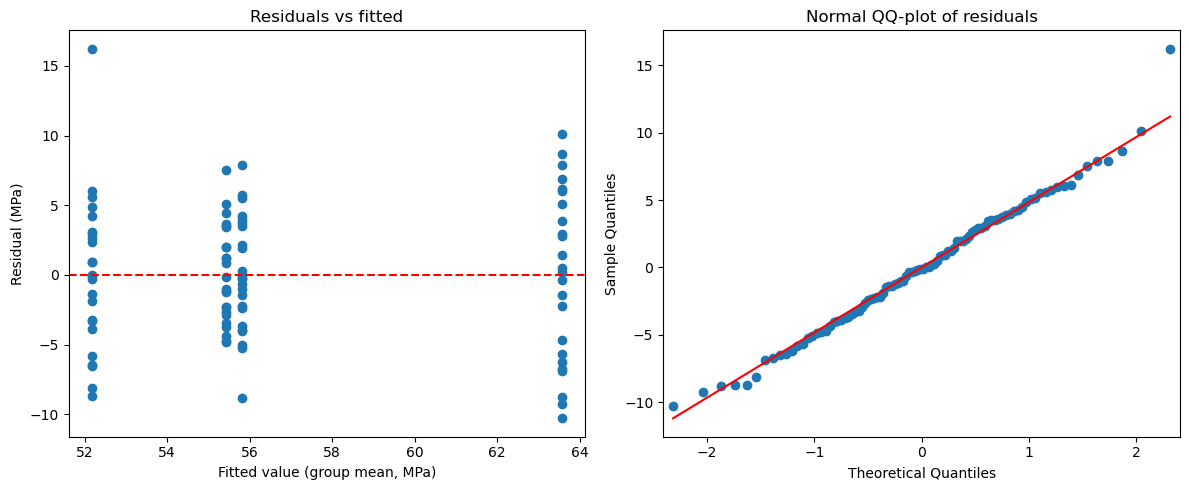

In [4]:

residuals = model.resid
fitted = model.fittedvalues

display(summary)
print("Largest SD / smallest SD =", round(summary["sd"].max() / summary["sd"].min(), 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(fitted, residuals)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Fitted value (group mean, MPa)")
axes[0].set_ylabel("Residual (MPa)")
axes[0].set_title("Residuals vs fitted")

sm.qqplot(residuals, line="s", ax=axes[1])
axes[1].set_title("Normal QQ-plot of residuals")

plt.tight_layout()
plt.show()

Independence: the study description says the specimens are independent, and each specimen is measured once. This cannot be checked in the plots. It would fail if, for example, several specimens were cut from the same panel or cured in the same batch. \
Group spreads: the SDs go from 3.4 MPa (UV) to 6.2 MPa (hybrid), so the largest is 1.8 times the smallest. Ambient and hybrid vary more than thermal and UV. \
Residual versus fitted: each column is one curing method. Hybrid and ambient are somewhat wider, but there is no strong funnel. Ambient specimen 13 (68.4 MPa) lies about 16 MPa above its group mean. \
QQ-plot of residuals: the points follow the line well, only specimen 13 sits above it in the upper tail. The normal-error approximation is reasonable.

The pooled raw strengths are not the right normality check because they mix four groups with different means. Even if the errors in every group are normal, the pooled values form a mixture that can look skewed or have several peaks. The model assumes normal errors around each group mean, so the residuals are what should be checked.

### b) Decide whether the classical common‑variance model is credible. Also run Welch's one‑way ANOVA as a sensitivity analysis and explain why it is not paired automatically with ordinary Tukey HSD.


In [5]:
from statsmodels.stats.oneway import anova_oneway

groups = [composite.loc[composite["curing_method"] == m, "strength_mpa"] for m in order]
levene_stat, levene_p = stats.levene(*groups)
print(f"Levene test: W = {levene_stat:.3f}, p = {levene_p:.4f}")

classical_F = anova_table.loc["C(curing_method)", "F"]
classical_p = anova_table.loc["C(curing_method)", "PR(>F)"]
print(f"Classical ANOVA: F = {classical_F:.3f}, p = {classical_p:.2e}")

welch = anova_oneway(composite["strength_mpa"], composite["curing_method"], use_var="unequal")
print(f"Welch ANOVA:     F = {welch.statistic:.3f}, df = ({welch.df_num:.0f}, {welch.df_denom:.2f}), p = {welch.pvalue:.2e}")

Levene test: W = 3.154, p = 0.0286
Classical ANOVA: F = 22.942, p = 3.55e-11
Welch ANOVA:     F = 15.567, df = (3, 49.94), p = 2.81e-07


The design is balanced (24 specimens per method) and the largest SD is less than twice the smallest. The residual plot shows somewhat larger spread for ambient and hybrid, and Levene's test (p = 0.029) also points to some difference in variance. A pre-test should not decide the model on its own, so we judge it together with the plots and the design. With equal group sizes the classical F-test is robust to moderate differences in spread, so the common-variance model is credible enough here.

Welch's ANOVA, which does not assume equal variances, gives F = 15.6 on (3, 49.9) df and p = 2.8e-07. It leads to the same conclusion as the classical ANOVA, so the global result does not depend on the equal-variance assumption.

Welch's ANOVA is not paired automatically with ordinary Tukey HSD. Tukey uses the pooled MS_within, which assumes one common variance. Welch drops that assumption, so its matching follow-up is Games–Howell. Here the classical model is kept, so classical ANOVA followed by Tukey is consistent.


### c) Calculate η² and interpret it as a descriptive fraction of observed squared variation, not causation.


In [6]:
ss_between = float(anova_table.loc["C(curing_method)", "sum_sq"])
ss_total = float(anova_table.loc["Total", "sum_sq"])

eta_squared = ss_between / ss_total
print(f"SS between = {ss_between:.2f}")
print(f"SS total   = {ss_total:.2f}")
print(f"eta^2      = {eta_squared:.3f}  ({eta_squared * 100:.1f}% of the observed variation)")

SS between = 1682.08
SS total   = 3930.49
eta^2      = 0.428  (42.8% of the observed variation)


$\eta^2 = 0.428$, so 42.8% of the observed squared variation in strength in this sample lies between the curing-method means, and the remaining 57.2% is variation between specimens cured the same way. \
This is a descriptive share for these 96 specimens. It does not mean that curing method causes 43% of the strength, because the data do not show how specimens were assigned to the methods.


### d) If the classical omnibus test is relevant and significant, perform Tukey HSD. Report simultaneous pairwise intervals and adjusted *p*‑values and identify which curing methods are distinguishable. Do not treat a non‑significant pair as proof of equal means.

  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1  group2 meandiff p-adj   lower    upper  reject
-------------------------------------------------------
ambient  hybrid  11.3937    0.0   7.6596 15.1279   True
ambient thermal     3.64 0.0589  -0.0942  7.3742  False
ambient      uv   3.2383 0.1129  -0.4958  6.9725  False
 hybrid thermal  -7.7538    0.0 -11.4879 -4.0196   True
 hybrid      uv  -8.1554    0.0 -11.8896 -4.4213   True
thermal      uv  -0.4017 0.9922  -4.1358  3.3325  False
-------------------------------------------------------


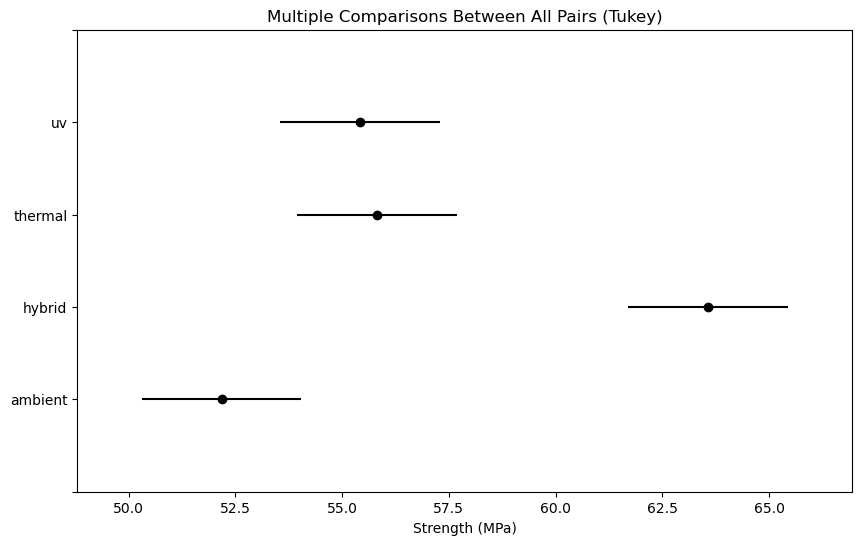

In [7]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

if classical_p < 0.05:
    tukey = pairwise_tukeyhsd(endog=composite["strength_mpa"], groups=composite["curing_method"], alpha=0.05)
    print(tukey.summary())

    tukey.plot_simultaneous()
    plt.xlabel("Strength (MPa)")
    plt.show()
else:
    print("Classical ANOVA not significant -> no post-hoc test needed")

The classical ANOVA was significant and judged credible in 2b, so Tukey HSD is used. The intervals are simultaneous 95% intervals and the p-values are adjusted for the six comparisons. \
Hybrid is distinguishable from all three other methods: 11.4 MPa above ambient (7.7 to 15.1), 7.8 MPa above thermal (4.0 to 11.5) and 8.2 MPa above UV (4.4 to 11.9), all with adjusted p < 0.001. \
Ambient, thermal and UV are not distinguishable (adjusted p = 0.059, 0.113 and 0.992). Their intervals include 0, but this does not prove equal means. The ambient–thermal interval goes up to 7.4 MPa, so a real difference of several MPa is still possible.

### e) Write a recommendation in MPa that distinguishes the global question, specific pairwise differences, practical importance, and design limitations.

Global question: Part 1d rejects $H_0$ ($F = 22.9$ on (3, 92) degrees of freedom , $p  \approx 3.6 \times 10^{-11}$), so mean strength is not the same for all four curing methods. The conclusion does not rely on assuming equal variance according to 2b.

Specific pairwise differences: the only method that stands out is hybrid according to Tukey HSD. Mean strength is higher than the other methods. 
- hybrid is about 11.4 MPa higher than ambient 
 
- hybrid is about 7.8 MPa higher than thermal

- hybrid is about 8.2 MPa higher than uv

based on the available data ambient, thermal and uv can't be told apart. The ambient–thermal interval goes from −0.1 to 7.4 MPa, so it is not impossible that there is a difference of a few MPa.

Practical importance: for hybrid a gain of 8–11 MPa matters, which is about 15–20% of the strength of the other methods.

Hybrid curing is a good idea when strength is a priority. Ambient, thermal and UV could not be told apart, but that does not show they are equal.

Design limitations: the data do not say how specimens were assigned to the methods, or whether material batch and test conditions were the same. The differences are therefore associations for these specimens, and a causal claim about curing method would need random assignment.

# Part 3 — Pump flow and energy use
#### The file *assignment05_pump_energy.csv* contains independent benchmark runs over an observed flow‑rate range. Let energy use be $Y$ and flow rate be $x$, with the statistical model $Y = \beta_0 + \beta_1 x + \epsilon$

### a) Identify the population, observational unit, response, predictor, and observed predictor range. Create a scatterplot and discuss whether a linear conditional‑mean model is plausible before fitting it.

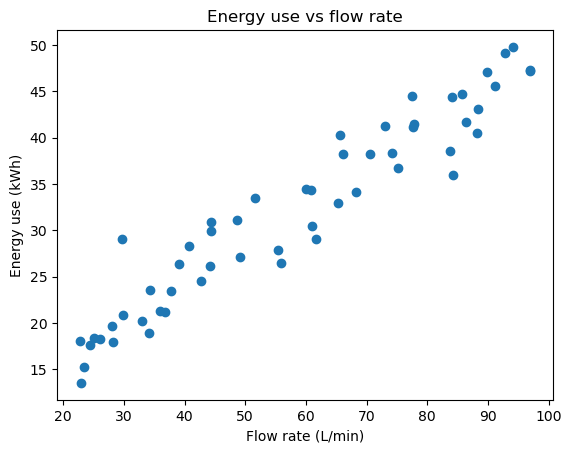


Population: all benchmark runs of this pump under the same test conditions, at flow rates between 22.7 and 97.0 L/min \
Observational unit: one benchmark run \
Response $Y$: energy use (kWh) \
Predictor $x$: flow rate (L/min) \
Observed range of $x$: 22.7 to 97.0 L/min, $n = 55$ runs \
Using the line outside this range would be extrapolation.

The points rise together in a roughly straight band. There is no clear curve and the spread around the band looks about the same at low and high flow, so a straight line for the mean energy use looks plausible. \
One run at about 30 L/min lies higher than its neighbours, and it should be checked with the residual plots in Part 4.


In [8]:
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
import pandas as pd

pump = pd.read_csv("assignment05_pump_energy.csv")
x = pump["flow_l_min"]
y = pump["energy_kwh"]
n = len(pump)

plt.scatter(x, y)
plt.xlabel("Flow rate (L/min)")
plt.ylabel("Energy use (kWh)")
plt.title("Energy use vs flow rate")
plt.show()

display(Markdown(f"""
Population: all benchmark runs of this pump under the same test conditions, at flow rates between {x.min()} and {x.max()} L/min \\
Observational unit: one benchmark run \\
Response $Y$: energy use (kWh) \\
Predictor $x$: flow rate (L/min) \\
Observed range of $x$: {x.min()} to {x.max()} L/min, $n = {n}$ runs \\
Using the line outside this range would be extrapolation.

The points rise together in a roughly straight band. There is no clear curve and the spread around the band looks about the same at low and high flow, so a straight line for the mean energy use looks plausible. \\
One run at about 30 L/min lies higher than its neighbours, and it should be checked with the residual plots in Part 4.
"""))

### b) Fit an intercept model with statsmodels. Report and interpret $\hat\beta_0$, $\hat\beta_1$, residual standard deviation, Pearson correlation $r$, and $R^2$. Include units and discuss whether the intercept has a useful engineering interpretation.


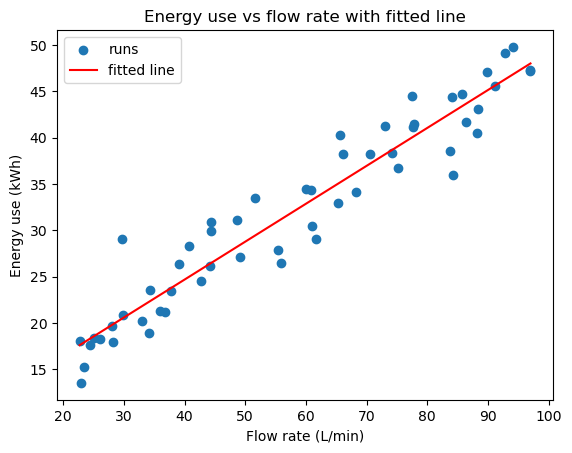


Fitted line: $\hat y = 8.318 + 0.4092\,x$ \
$\hat\beta_0 = 8.318$ kWh \
$\hat\beta_1 = 0.4092$ kWh per L/min \
Residual standard deviation $s = 2.938$ kWh \
Pearson correlation $r = 0.958$ \
$R^2 = 0.918$

Slope: each extra L/min of flow is associated with 0.409 kWh higher mean energy use, so 10 L/min more gives about 4.09 kWh more on average. \
Residual standard deviation: a single run typically lies about 2.94 kWh above or below the line. \
$r$: there is a strong positive linear association between flow rate and energy use. \
$R^2$: about 91.8% of the variation in energy use is accounted for by the line.

Intercept: 8.32 kWh would be the mean energy use at 0 L/min. Zero flow is far outside the observed range (22.7 to 97.0 L/min), so this is extrapolation. The intercept only anchors the line and should not be read as the energy use of an idle pump.


In [9]:
import statsmodels.formula.api as smf
import numpy as np

model = smf.ols("energy_kwh ~ flow_l_min", data=pump).fit()

b0 = model.params["Intercept"]
b1 = model.params["flow_l_min"]
s = np.sqrt(model.scale)
r = x.corr(y)
r2 = model.rsquared

plt.scatter(x, y, label="runs")
plt.plot(x, b0 + b1 * x, color="red", label="fitted line")
plt.xlabel("Flow rate (L/min)")
plt.ylabel("Energy use (kWh)")
plt.title("Energy use vs flow rate with fitted line")
plt.legend()
plt.show()

display(Markdown(rf"""
Fitted line: $\hat y = {b0:.3f} + {b1:.4f}\,x$ \
$\hat\beta_0 = {b0:.3f}$ kWh \
$\hat\beta_1 = {b1:.4f}$ kWh per L/min \
Residual standard deviation $s = {s:.3f}$ kWh \
Pearson correlation $r = {r:.3f}$ \
$R^2 = {r2:.3f}$

Slope: each extra L/min of flow is associated with {b1:.3f} kWh higher mean energy use, so 10 L/min more gives about {10*b1:.2f} kWh more on average. \
Residual standard deviation: a single run typically lies about {s:.2f} kWh above or below the line. \
$r$: there is a strong positive linear association between flow rate and energy use. \
$R^2$: about {r2*100:.1f}% of the variation in energy use is accounted for by the line.

Intercept: {b0:.2f} kWh would be the mean energy use at 0 L/min. Zero flow is far outside the observed range ({x.min()} to {x.max()} L/min), so this is extrapolation. The intercept only anchors the line and should not be read as the energy use of an idle pump.
"""))




### c) Verify that $R^2$ = $r^2$ for this simple intercept model. Explain what correlation and $R^2$ measure and what they do not establish.





In [10]:
display(Markdown(rf"""
$r = {r:.4f}$ \
$r^2 = {r**2:.4f}$ \
$R^2 = {r2:.4f}$ \
$R^2 = r^2$: {np.isclose(r2, r**2)}

The correlation $r$ measures the direction and how closely the points follow a straight line. It lies between $-1$ and $1$ and has no units. Here $r = {r:.3f}$ is a strong positive linear association. \
$R^2$ measures the share of the variation in energy use that the line accounts for, here about {r2*100:.1f}%.

Neither tells how much energy changes with flow. That is the slope, {b1:.3f} kWh per L/min. \
A high $r$ or $R^2$ does not show that flow causes the energy use. The file does not show that the flow settings were run in random order, and something else could change together with flow. \
A high $R^2$ also does not show that a straight line is the right model. That has to be checked with the residual plots. \
An $r$ close to 0 would not mean no relationship, since a curved relationship can have $r$ near 0.
"""))


$r = 0.9581$ \
$r^2 = 0.9179$ \
$R^2 = 0.9179$ \
$R^2 = r^2$: True

The correlation $r$ measures the direction and how closely the points follow a straight line. It lies between $-1$ and $1$ and has no units. Here $r = 0.958$ is a strong positive linear association. \
$R^2$ measures the share of the variation in energy use that the line accounts for, here about 91.8%.

Neither tells how much energy changes with flow. That is the slope, 0.409 kWh per L/min. \
A high $r$ or $R^2$ does not show that flow causes the energy use. The file does not show that the flow settings were run in random order, and something else could change together with flow. \
A high $R^2$ also does not show that a straight line is the right model. That has to be checked with the residual plots. \
An $r$ close to 0 would not mean no relationship, since a curved relationship can have $r$ near 0.


### d) Test $H_0$: $\beta_1 = 0$ against a two‑sided alternative. Report the slope estimate, standard error, 95 % interval, $t$‑statistic, degrees of freedom, and $p$‑value. State the conclusion as an association, not automatically as causation.

In [11]:
se_b1 = model.bse["flow_l_min"]
t_obs = model.tvalues["flow_l_min"]
p_b1 = model.pvalues["flow_l_min"]
df_res = int(model.df_resid)
ci_low, ci_high = model.conf_int(alpha=0.05).loc["flow_l_min"]

display(Markdown(rf"""
$H_0$: $\beta_1 = 0$ (no linear association between flow rate and mean energy use) \
$H_1$: $\beta_1 \neq 0$ \
$\alpha = 0.05$

Slope estimate $\hat\beta_1 = {b1:.4f}$ kWh per L/min \
Standard error $SE(\hat\beta_1) = {se_b1:.4f}$ kWh per L/min \
95% confidence interval: [{ci_low:.3f}, {ci_high:.3f}] kWh per L/min \
$t = \hat\beta_1 / SE(\hat\beta_1) = {t_obs:.2f}$ \
$df = n - 2 = {df_res}$ \
two-sided $p$-value $= {p_b1:.2e}$

Since $p < 0.05$, $H_0$ is rejected. The 95% interval does not contain 0, which agrees with the test. \
Mean energy use increases with flow rate, by about {b1:.3f} kWh per L/min (between {ci_low:.3f} and {ci_high:.3f}). \
This is an association. It does not by itself show that flow rate causes the energy use, because the data do not show that the flow settings were assigned in random order and other conditions could change together with flow.
"""))


$H_0$: $\beta_1 = 0$ (no linear association between flow rate and mean energy use) \
$H_1$: $\beta_1 \neq 0$ \
$\alpha = 0.05$

Slope estimate $\hat\beta_1 = 0.4092$ kWh per L/min \
Standard error $SE(\hat\beta_1) = 0.0168$ kWh per L/min \
95% confidence interval: [0.375, 0.443] kWh per L/min \
$t = \hat\beta_1 / SE(\hat\beta_1) = 24.35$ \
$df = n - 2 = 53$ \
two-sided $p$-value $= 1.90e-30$

Since $p < 0.05$, $H_0$ is rejected. The 95% interval does not contain 0, which agrees with the test. \
Mean energy use increases with flow rate, by about 0.409 kWh per L/min (between 0.375 and 0.443). \
This is an association. It does not by itself show that flow rate causes the energy use, because the data do not show that the flow settings were assigned in random order and other conditions could change together with flow.


# Part 4 — Regression diagnostics and prediction
#### Continue with the pump study.

### a) Create residual‑versus‑fitted, residual‑versus‑run‑order, and normal QQ‑plots. Discuss linearity, constant spread, unusual observations, normal‑error approximation, and what the plots cannot establish about independence or sampling.

In [12]:
print(model.summary(slim=True))

                            OLS Regression Results                            
Dep. Variable:             energy_kwh   R-squared:                       0.918
Model:                            OLS   Adj. R-squared:                  0.916
No. Observations:                  55   F-statistic:                     592.9
Covariance Type:            nonrobust   Prob (F-statistic):           1.90e-30
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      8.3180      1.051      7.916      0.000       6.211      10.426
flow_l_min     0.4092      0.017     24.349      0.000       0.375       0.443

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.


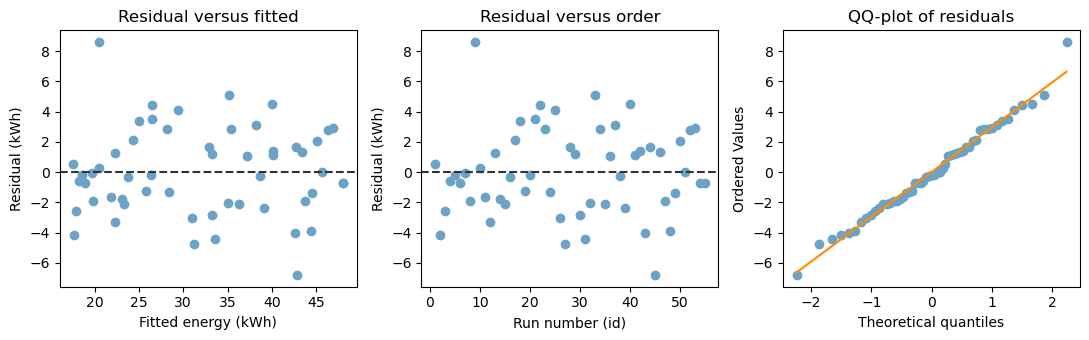


Linearity: the residual versus fitted plot shows no curve, the residuals are scattered around 0 across the whole range. \
Constant spread: there is no funnel, the residuals spread about the same at low and high fitted energy. \
Unusual observations: run 9 has a residual of 8.6 kWh (about 3 residual SDs) and run 45 a residual of -6.8 kWh. They are looked at in 4b. \
Normal errors: the QQ-plot follows the line closely, only run 9 sits above it in the upper tail, so the normal-error approximation is reasonable.

Residual versus run order shows no trend or drift. However, the run numbers increase with the flow rate, so this plot looks almost the same as the fitted plot and cannot separate a time effect from a flow effect. \
The plots cannot show whether the runs were independent or how they were selected. That has to come from the study design, for example whether the flow settings were run in random order and on which pump.


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
axes[0].scatter(model.fittedvalues, model.resid, color="#6CA2C6")
axes[0].axhline(0, color="0.2", linestyle="--")
axes[0].set_xlabel("Fitted energy (kWh)")
axes[0].set_ylabel("Residual (kWh)")
axes[0].set_title("Residual versus fitted")

axes[1].scatter(pump["run_id"], model.resid, color="#6CA2C6")
axes[1].axhline(0, color="0.2", linestyle="--")
axes[1].set_xlabel("Run number (id)")
axes[1].set_ylabel("Residual (kWh)")
axes[1].set_title("Residual versus order")

stats.probplot(model.resid, dist="norm", plot=axes[2])
axes[2].get_lines()[0].set_markerfacecolor("#6CA2C6")
axes[2].get_lines()[0].set_markeredgecolor("#6CA2C6")
axes[2].get_lines()[1].set_color("#FF8C00")
axes[2].set_title("QQ-plot of residuals")
plt.tight_layout()
plt.show()
res9 = model.resid[pump["run_id"] == 9].iloc[0]
res45 = model.resid[pump["run_id"] == 45].iloc[0]
display(Markdown(rf"""
Linearity: the residual versus fitted plot shows no curve, the residuals are scattered around 0 across the whole range. \
Constant spread: there is no funnel, the residuals spread about the same at low and high fitted energy. \
Unusual observations: run 9 has a residual of {res9:.1f} kWh (about 3 residual SDs) and run 45 a residual of {res45:.1f} kWh. They are looked at in 4b. \
Normal errors: the QQ-plot follows the line closely, only run 9 sits above it in the upper tail, so the normal-error approximation is reasonable.

Residual versus run order shows no trend or drift. However, the run numbers increase with the flow rate, so this plot looks almost the same as the fitted plot and cannot separate a time effect from a flow effect. \
The plots cannot show whether the runs were independent or how they were selected. That has to come from the study design, for example whether the flow settings were run in random order and on which pump.
"""))

### b) Calculate leverage and Cook’s distance. Identify the most influential run, investigate it rather than deleting it automatically, and explain what operational information you would seek.







In [14]:
infl = model.get_influence()
leverage = infl.hat_matrix_diag
cooks = infl.cooks_distance[0]
flag = np.argmax(cooks)

influence = pump.assign(residual=model.resid, leverage=leverage, cooks_d=cooks)
display(influence.sort_values("cooks_d", ascending=False).head(3).round(3))

top_lev = influence.sort_values("leverage", ascending=False).head(2)
model_wo = smf.ols("energy_kwh ~ flow_l_min", data=pump.drop(index=flag)).fit()

display(Markdown(rf"""
Most influential run: run {int(pump.loc[flag, 'run_id'])} (flow {pump.loc[flag, 'flow_l_min']} L/min, energy {pump.loc[flag, 'energy_kwh']} kWh), Cook's distance $= {cooks[flag]:.3f}$, leverage $= {leverage[flag]:.3f}$ \
Its leverage is low because its flow is not far from the other runs. It is influential because of its large residual ({model.resid[flag]:.1f} kWh), and in the data it is a sudden jump from about 18–20 kWh to 29 kWh. \
The highest leverage is at the top of the flow range (runs {', '.join(str(i) for i in top_lev['run_id'])}, leverage {top_lev['leverage'].max():.3f}), but these runs lie close to the line. \
Without run 9 the slope changes from {model.params['flow_l_min']:.3f} to {model_wo.params['flow_l_min']:.3f} kWh per L/min, so the conclusion does not depend on this one run.

Run 9 is kept in the analysis. Before deciding anything we would check the run log: whether the energy meter and flow sensor were calibrated, whether the pump had just started or was warming up, whether the valve setting or fluid temperature was different, and whether there was air in the line or a blockage. If a recording or setup error is found, the run can be corrected or excluded with a stated reason. Otherwise it is a real run and stays in.
"""))

,run_id,flow_l_min,energy_kwh,residual,leverage,cooks_d
8,9,29.74,29.085,8.598,0.044,0.207
44,45,84.24,35.978,-6.810,0.041,0.119
1,2,22.93,13.534,-4.167,0.058,0.066



Most influential run: run 9 (flow 29.74 L/min, energy 29.085 kWh), Cook's distance $= 0.207$, leverage $= 0.044$ \
Its leverage is low because its flow is not far from the other runs. It is influential because of its large residual (8.6 kWh), and in the data it is a sudden jump from about 18–20 kWh to 29 kWh. \
The highest leverage is at the top of the flow range (runs 55, 54, leverage 0.068), but these runs lie close to the line. \
Without run 9 the slope changes from 0.409 to 0.417 kWh per L/min, so the conclusion does not depend on this one run.

Run 9 is kept in the analysis. Before deciding anything we would check the run log: whether the energy meter and flow sensor were calibrated, whether the pump had just started or was warming up, whether the valve setting or fluid temperature was different, and whether there was air in the line or a blockage. If a recording or setup error is found, the run can be corrected or excluded with a stated reason. Otherwise it is a real run and stays in.


### c) At $x_0$ = 70 L/min, report the fitted mean energy, a 95 % confidence interval for the mean energy, and a 95 % prediction interval for one new run. Explain why the prediction interval is wider.



In [15]:
pred = model.get_prediction(pd.DataFrame({"flow_l_min": [70]}))
frame = pred.summary_frame(alpha=0.05)
mean = frame["mean"].values[0]
mean_ci_lower = frame["mean_ci_lower"].values[0]
mean_ci_upper = frame["mean_ci_upper"].values[0]
obs_ci_lower = frame["obs_ci_lower"].values[0]
obs_ci_upper = frame["obs_ci_upper"].values[0]

print(frame[["mean", "mean_ci_lower", "mean_ci_upper", "obs_ci_lower", "obs_ci_upper"]])
display(Markdown(f"""
mean $= {mean:.3f}$ \\
95% interval for entire mean $= {mean_ci_lower:.3f} - {mean_ci_upper:.3f}$ \\
95% interval for single run $= {obs_ci_lower:.3f} - {obs_ci_upper:.3f}$ \\
The confidence interval only covers the uncertainty about where the true mean line is, which gets smaller with more runs. \\
The prediction interval also includes the scatter of one run around that mean (residual SD about {np.sqrt(model.scale):.2f} kWh). This part does not shrink with more data, so the prediction interval is always wider.
"""))

        mean  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  36.961036      36.067983      37.854089     31.000364     42.921708



mean $= 36.961$ \
95% interval for entire mean $= 36.068 - 37.854$ \
95% interval for single run $= 31.000 - 42.922$ \
The confidence interval only covers the uncertainty about where the true mean line is, which gets smaller with more runs. \
The prediction interval also includes the scatter of one run around that mean (residual SD about 2.94 kWh). This part does not shrink with more data, so the prediction interval is always wider.




### d) Explain why using this fitted line at 10 or 120 L/min would be extrapolation. State what evidence would be needed before extending the relationship outside the observed range.



In [16]:
display(Markdown(rf"""
The line was fitted only on flows from {pump['flow_l_min'].min()} to {pump['flow_l_min'].max()} L/min. 10 L/min is below and 120 L/min is above this range, so the data cannot show whether energy use still changes linearly there. \
Pump behaviour can change outside the tested range, for example lower efficiency at very low flow or a steeper rise near maximum flow, so the line could be wrong there even though it fits well inside the range.

Before using the line at 10 or 120 L/min we would need new benchmark runs at and around those flows, ideally in random order, and check that they follow the same line with the same spread. The manufacturer's pump curve could support this, but it does not replace measurements.
"""))


The line was fitted only on flows from 22.7 to 97.0 L/min. 10 L/min is below and 120 L/min is above this range, so the data cannot show whether energy use still changes linearly there. \
Pump behaviour can change outside the tested range, for example lower efficiency at very low flow or a steeper rise near maximum flow, so the line could be wrong there even though it fits well inside the range.

Before using the line at 10 or 120 L/min we would need new benchmark runs at and around those flows, ideally in random order, and check that they follow the same line with the same spread. The manufacturer's pump curve could support this, but it does not replace measurements.


### e) Give a practical conclusion that includes slope in kWh per L min, uncertainty, residual variation, $R^2$, prediction uncertainty, and study‑design limitations.


In [17]:
i = []
t = 0

for x in range(23, 97):
    i.append(x)
    pred = model.get_prediction(pd.DataFrame({"flow_l_min": [x]}))
    frame = pred.summary_frame(alpha=0.05)
    obs_ci_lower = frame["obs_ci_lower"].values[0]
    obs_ci_upper = frame["obs_ci_upper"].values[0]
    t += (obs_ci_upper - obs_ci_lower)
mean_prediction_uncertanty = t / len(i)
mean_prediction_uncertanty

11.98052498857776

In [18]:
slope = model.params["flow_l_min"]
slope_ci_min, slope_ci_max = model.conf_int().loc["flow_l_min"]
s_res = np.sqrt(model.scale)
r_squared = model.rsquared

display(Markdown(rf"""
Across {len(pump)} benchmark runs, mean energy use increased by {slope:.3f} kWh per L/min of flow (95% CI {slope_ci_min:.3f} to {slope_ci_max:.3f} kWh per L/min), so 10 L/min more flow goes with about {10*slope:.1f} kWh more energy on average. \
The line accounts for $R^2 = {r_squared:.3f}$ of the variation, and single runs scatter around it with a residual SD of $s = {s_res:.2f}$ kWh. \
The 95% prediction interval for one new run is on average {mean_prediction_uncertanty:.1f} kWh wide (about ±{mean_prediction_uncertanty/2:.1f} kWh), so the line predicts the mean energy well but a single run much less precisely.

Limitations: the result only covers this pump and flows from {pump['flow_l_min'].min()} to {pump['flow_l_min'].max()} L/min. The data do not show that the flow settings were run in random order, so the slope is an association and not a proven causal effect. Run 9 should be checked in the run log before the results are used.
"""))


Across 55 benchmark runs, mean energy use increased by 0.409 kWh per L/min of flow (95% CI 0.375 to 0.443 kWh per L/min), so 10 L/min more flow goes with about 4.1 kWh more energy on average. \
The line accounts for $R^2 = 0.918$ of the variation, and single runs scatter around it with a residual SD of $s = 2.94$ kWh. \
The 95% prediction interval for one new run is on average 12.0 kWh wide (about ±6.0 kWh), so the line predicts the mean energy well but a single run much less precisely.

Limitations: the result only covers this pump and flows from 22.7 to 97.0 L/min. The data do not show that the flow settings were run in random order, so the slope is an association and not a proven causal effect. Run 9 should be checked in the run log before the results are used.


# Part 5 — AI‑use and conclusion
#### AI‑use
State which AI tools you used, what they contributed, what you changed or rejected, and how you verified the work. A short paragraph or table is sufficient.

Claude was used to explain the Session 9 and 10 theory for our own understanding. These explanations were double checked and studied with the session notes and Brooks chapters 9–10. \
It also helped with statsmodels syntax (anova_lm, anova_oneway, pairwise_tukeyhsd, get_influence, get_prediction), and reviewed the finished parts against the assignment checklist, pointing out missing items, weak explanations and formatting issues. VS Code autocomplete was also used for syntax.

Suggestions were only kept when they matched the course material, and text was edited into our own words.

#### Overall conclusion
Write approximately 150–250 words comparing ANOVA and regression as methods for a quantitative response. Explain how the type of predictor determines the question, how residuals are used in both analyses, and why statistical modelling does not by itself prove causation.

ANOVA and regression both model a quantitative response as a systematic part plus random error, and both split the total variation into an explained part and a residual part.

The type of predictor decides the question. In ANOVA the predictor is categorical, so the question is whether the group means differ and, if they do, which ones. For the composites, mean strength differed between curing methods ($F = 22.9$, $p < 0.001$, $\eta^2 = 0.43$), and Tukey HSD showed that hybrid was 7.8 to 11.4 MPa stronger than the other three methods. In regression the predictor is quantitative, so the question is how much the mean response changes per unit of $x$. For the pump, mean energy use rose by 0.409 kWh per L/min (95% CI 0.375 to 0.443) with $R^2 = 0.92$.

Residuals are used in the same way in both analyses. They are the observed values minus the fitted group mean or fitted line, and residual plots and QQ-plots are used to check constant spread, normal errors and unusual points. In ANOVA they showed somewhat larger spread for hybrid and ambient, and in regression they showed no curve and one unusual run.

Neither model proves causation. A small $p$-value only says the pattern is unlikely to be chance. A causal claim needs random assignment of curing methods or flow settings, which the data do not document, so both results are associations within the tested conditions and range.